## Algoritmo general de Gradient Boosting Trees, explicación de libro

Dado un conjunto de datos $\{(x_i, y_i)\}_{i=1}^n$, una función de pérdida $L(y, F(x))$, y un número de iteraciones $M$:

### 1. Inicialización

Inicializa el modelo con una constante:

$$
F_0(x) = \arg\min_{\gamma} \sum_{i=1}^n L(y_i, \gamma)
$$

### 2. Para $m = 1, 2, \dots, M$

#### (A) Calcular los pseudoresiduos

Para cada observación $i = 1, \dots, n$:

$$
r_{im} = - \left[ \frac{\partial L(y_i, F(x_i))}{\partial F(x_i)} \right]_{F(x)=F_{m-1}(x)}
$$

#### (B) Ajustar un árbol de regresión

Ajusta un árbol de regresión a los valores $\{r_{im}\}_{i=1}^n$, obteniendo $J_m$ regiones terminales $\{R_{jm}\}_{j=1}^{J_m}$.

#### (C) Calcular el valor óptimo en cada hoja

Para cada región terminal $j = 1, \dots, J_m$:

$$
\gamma_{jm} = \arg\min_{\gamma} \sum_{x_i \in R_{jm}} L\left(y_i, F_{m-1}(x_i) + \gamma \right)
$$

#### (D) Actualizar el modelo

$$
F_m(x) = F_{m-1}(x) + \nu \sum_{j=1}^{J_m} \gamma_{jm} I(x \in R_{jm})
$$

donde $\nu \in (0,1]$ es el learning rate.

### 3. Modelo final

$$
F_M(x) = F_0(x) + \nu \sum_{m=1}^M \sum_{j=1}^{J_m} \gamma_{jm} I(x \in R_{jm})
$$

## Gradient Boosting Trees (interpretación intuitiva)

La idea central de GBT es:

> Construir el modelo como una suma de árboles que corrigen errores anteriores.

---

## 1. Inicialización

$$
F_0(x) = \arg\min_{\gamma} \sum_{i=1}^n L(y_i, \gamma)
$$

### Interpretación

- Empiezas con la mejor predicción constante.
- En regresión con MSE:

$$
F_0(x) = \bar{y}
$$

👉 Es decir: **empiezas prediciendo el promedio**.

---

## 2. Para $m = 1, 2, ..., M$

### (A) Calcular pseudoresiduos

$$
r_{im} = - \left[ \frac{\partial L(y_i, F(x_i))}{\partial F(x_i)} \right]_{F=F_{m-1}}
$$

### Interpretación

- Son los **errores del modelo actual**.
- En MSE:

$$
r_{im} = y_i - F_{m-1}(x_i)
$$

👉 Es decir: **los residuales clásicos**.

---

### (B) Ajustar un árbol a los residuales

👉 Entrenas un árbol para predecir:

$$
r_{im}
$$

### Interpretación

- El árbol aprende:
  
> "¿Dónde se está equivocando el modelo?"

- No predice $y$, predice **errores**.

---

### (C) Encontrar cuánto ajustar (gamma)

$$
\gamma_{jm} = \arg\min_{\gamma} \sum_{x_i \in R_{jm}} L\left(y_i, F_{m-1}(x_i) + \gamma \right)
$$

### Interpretación

- Para cada hoja del árbol:
  
👉 decides **cuánto corregir** la predicción.

- En MSE:

$$
\gamma_{jm} = \text{promedio de residuales en la hoja}
$$

---

### (D) Actualizar el modelo

$$
F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x)
$$

donde:

$$
h_m(x) = \sum_{j=1}^{J_m} \gamma_{jm} I(x \in R_{jm})
$$

### Interpretación clave

👉 El modelo es:

$$
\text{predicción nueva} = \text{predicción anterior} + \alpha \cdot \text{árbol de residuales}
$$

- $\nu$ (learning rate) = $\alpha$
- El árbol predice errores
- Solo corriges **un poco** cada vez

---

## 3. Modelo final

$$
F_M(x) = \bar{y} + \nu \sum_{m=1}^M h_m(x)
$$

---

## Intuición global (lo más importante)

El modelo es:

$$
\text{predicción} = \text{promedio} + \text{suma de correcciones}
$$

o más explícito:

$$
\hat{y} = \bar{y} + \alpha \cdot (\text{error}_1) + \alpha \cdot (\text{error}_2) + ...
$$

---

## Interpretación tipo "ingeniero"

1. Empiezas con algo muy simple (promedio)
2. Iterativamente haces:

   - Calculas error
   - Aprendes el error con un árbol
   - Corriges un poco

3. Repites muchas veces

---

## Insight clave (muy importante)

GBT es:

> **Gradient descent en el espacio de funciones**

- No optimizas parámetros directamente
- Cada árbol es un **paso de gradiente**

---

## Frase mental para recordar

> GBT = promedio + suma de árboles que corrigen errores * learning rate

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.inspection import PartialDependenceDisplay


Cargar y limpiar datos

In [2]:
housing = pd.read_csv('housing.csv')
housing = pd.get_dummies(housing, drop_first=True)
housing['total_bedrooms'] = housing['total_bedrooms'].fillna(housing['total_bedrooms'].mean())
target = 'median_house_value'
X = housing.copy().drop(target, axis=1)
y = housing[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
# Entrenar modelo de gradient boosting trees
from sklearn.ensemble import GradientBoostingRegressor
model=GradientBoostingRegressor(max_depth=5, n_estimators=100, learning_rate=0.1)
model.fit(X_train,y_train)
# Predicciones
predicciones=model.predict(X_test)
# Evaluación
r2_score(y_pred=predicciones,y_true=y_test)

0.803551297934979

In [18]:
## Cross validation 
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline=Pipeline([
    ('gbt',GradientBoostingRegressor())
])

params={
    'gbt__max_depth':[3,4,5,6,7,8],
    'gbt__learning_rate':[0.01,0.05,0.1,0.5],
    'gbt__n_estimators':[50,100,200]
}

grid_gbt=GridSearchCV(estimator=pipeline,cv=3,param_grid=params,scoring='r2',n_jobs=-1)
grid_gbt.fit(X_train,y_train)


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('gbt', GradientBoostingRegressor())]),
             n_jobs=-1,
             param_grid={'gbt__learning_rate': [0.01, 0.05, 0.1, 0.5],
                         'gbt__max_depth': [3, 4, 5, 6, 7, 8],
                         'gbt__n_estimators': [50, 100, 200]},
             scoring='r2')

In [20]:
grid_gbt.best_estimator_.named_steps['gbt']

GradientBoostingRegressor(max_depth=8, n_estimators=200)

grid_gbt.best_estimator_.named_steps['gbt']

In [21]:
# Mejor estimador 
prediccciones=grid_gbt.predict(X_test)


In [22]:
# r2 score
r2_score(y_pred=prediccciones,y_true=y_test)

0.8291352708080875

In [23]:
## Calibracion


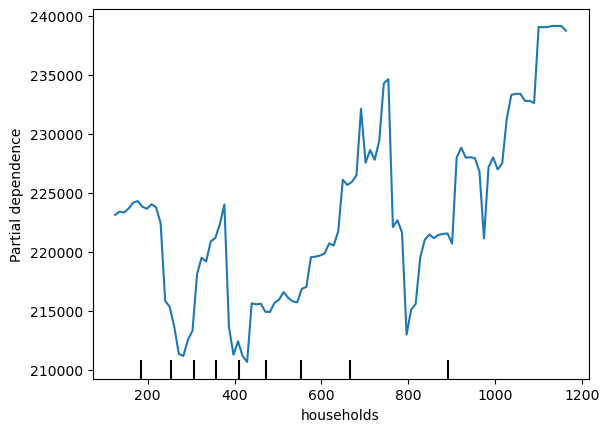

Exception ignored in: <function ResourceTracker.__del__ at 0x104b65bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1086e1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x105ecdbc0>
Traceback (most recent call last

In [ ]:
# Entendiendo el modelo 
PartialDependenceDisplay.from_estimator(
    grid_gbt,
    X_train,
    [6],
    feature_names=X_train.columns
    )

    PartialDependenceDisplay.from_estimator(
        best_grid_gbt,
        X_train,
        [i],
        feature_names=X_train.columns
    )

In [25]:
# Codigo for para partial dependence plot 
